# BERT Family — BERT vs RoBERTa vs DistilBERT

## 1. Overview

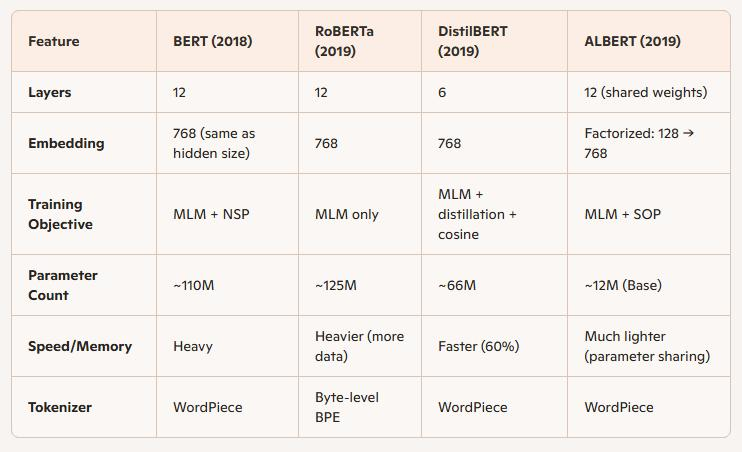

BERT-family models are **pretrained encoder-only Transformer models** designed primarily for NLP understanding tasks.

The key distinction:

| Model          | Main idea                                           |
| -------------- | --------------------------------------------------- |
| **BERT**       | Original pretrained bidirectional encoder           |
| **RoBERTa**    | Better-trained BERT-style encoder                   |
| **DistilBERT** | Smaller, faster BERT through knowledge distillation |

---

## 2. BERT

### Architecture

- **Encoder-only Transformer**
- BERT-Base:
  - 12 Transformer encoder layers
  - 12 attention heads
  - Hidden size = 768
  - \~110M parameters
- Uses **WordPiece** tokenization.
```
Input
  ↓
WordPiece tokens
  ↓
BERT Encoder × 12
  ↓
Contextual representations
```

### Pretraining Objective

Original BERT uses:

1. **Masked Language Modeling (MLM)**
2. **Next Sentence Prediction (NSP)**

\\[ \mathcal{L}\_{BERT} = \mathcal{L}\_{MLM} + \mathcal{L}\_{NSP} \\]

### Downstream Use

Fine-tune BERT with task-specific heads:
```
BERT
 │
 ├── Sequence Classification
 ├── Token Classification / NER
 └── Extractive Question Answering
```

**Mental model:** &#x20;

> BERT = **Original pretrained encoder**

---

# 3. RoBERTa

**RoBERTa = Robustly Optimized BERT Approach**

### Architecture

RoBERTa is fundamentally a **BERT-style encoder**, rather than a radically different architecture.

For the base configuration:

- 12 Transformer layers
- 12 attention heads
- Hidden size = 768
- Uses **byte-level BPE** tokenization.

### Pretraining Objective

RoBERTa removes the original NSP objective and focuses on improved MLM-based pretraining.

Important changes include:

- **No NSP**
- **Dynamic masking**
- More training data
- Larger batches
- Longer training
- Improved training recipe
```
BERT:
MLM + NSP

RoBERTa:
Improved MLM-based training
+ no NSP
+ dynamic masking
```

### Downstream Use

Same general family of tasks:
```
RoBERTa
   ↓
Sequence Classification
Token Classification
Extractive QA
```

**Mental model:** &#x20;

> RoBERTa = **Better-trained BERT**

---

# 4. DistilBERT

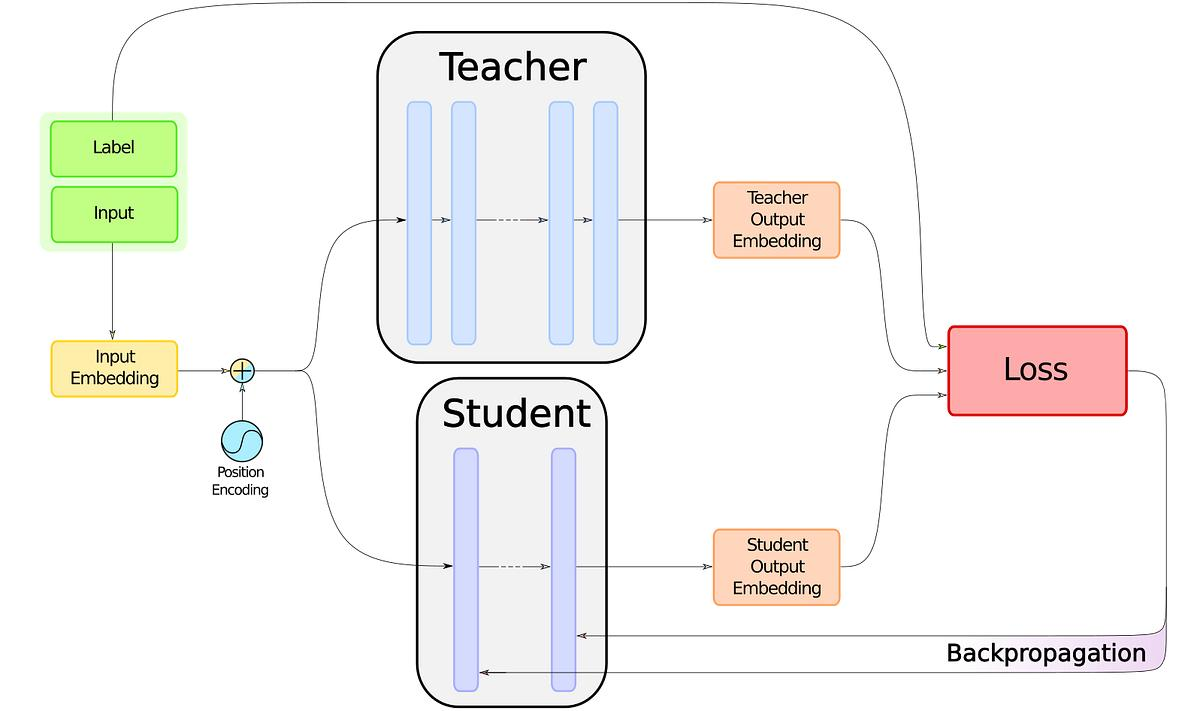


DistilBERT focuses on **model compression and efficiency**.

### Architecture

BERT-Base:

\\[ 12 \text{ layers} \\]

DistilBERT:

\\[ 6 \text{ layers} \\]

It retains:

- 12 attention heads
- Hidden size = 768
```
BERT Teacher
12 layers
     │
     │ Knowledge Distillation
     ▼
DistilBERT Student
6 layers
```

### Pretraining Objective

DistilBERT combines:

1. **Masked Language Modeling**
2. **Distillation loss**
3. **Cosine-distance / representation similarity loss**

Conceptually:

\\[ \mathcal{L} = \mathcal{L}\_{LM} + \mathcal{L}\_{distill} + \mathcal{L}\_{cos} \\]

The teacher provides information that helps the smaller student reproduce useful behavior.

### Downstream Use

Can be fine-tuned for:

- Sequence classification
- Token classification
- Extractive QA
- Other encoder-based NLP tasks

**Mental model:** &#x20;

> DistilBERT = **Smaller and faster BERT**

---

# 5. Comparison

| Feature                | **BERT**                    | **RoBERTa**              | **DistilBERT**          |
| ---------------------- | --------------------------- | ------------------------ | ----------------------- |
| Architecture           | Encoder-only                | BERT-style encoder       | Smaller encoder         |
| Main goal              | Original pretrained encoder | Better pretraining       | Model compression       |
| Base layers            | 12                          | 12                       | 6                       |
| Hidden size            | 768                         | 768                      | 768                     |
| Attention heads        | 12                          | 12                       | 12                      |
| Tokenizer              | WordPiece                   | Byte-level BPE           | WordPiece               |
| MLM                    | ✅                           | ✅                        | ✅                       |
| NSP                    | ✅ Original                  | ❌                        | ❌                       |
| Dynamic masking        | Original recipe             | ✅                        | Not defining feature    |
| Knowledge distillation | ❌                           | ❌                        | ✅                       |
| Main advantage         | Foundation                  | Stronger training recipe | Efficiency              |
| Downstream tasks       | Classification, NER, QA     | Classification, NER, QA  | Classification, NER, QA |

---

# 6. Architecture → Objective → Downstream Use

## BERT
```
Architecture:
Encoder-only Transformer
        ↓
Objective:
MLM + NSP
        ↓
Downstream:
Classification / NER / QA
```

## RoBERTa
```
Architecture:
BERT-style Encoder
        ↓
Objective:
Improved MLM-based pretraining
+ No NSP
+ Dynamic masking
        ↓
Downstream:
Classification / NER / QA
```

## DistilBERT
```
Architecture:
Smaller BERT-style Encoder
        ↓
Objective:
MLM + Distillation + Representation similarity
        ↓
Downstream:
Classification / NER / QA
```

---

# 7. Why These Models Exist
```
                 BERT
                   │
          "Pretrain an encoder"
                   │
                   ▼
               RoBERTa
                   │
       "Train it more effectively"
                   │
                   ▼
             DistilBERT
                   │
        "Make it smaller/faster"
```

### Simple memory trick

> **BERT → Original**\
> **RoBERTa → Optimized**\
> **DistilBERT → Compressed**

---

# 8. Model Selection

| Requirement                          | Consider                      |
| ------------------------------------ | ----------------------------- |
| Learn the original BERT architecture | BERT                          |
| Strong BERT-style encoder baseline   | RoBERTa                       |
| Lower memory / latency               | DistilBERT                    |
| Resource-constrained deployment      | DistilBERT                    |
| General NLP understanding            | BERT / RoBERTa                |
| Production choice                    | Benchmark on your actual task |

Model choice should ultimately consider:

- Accuracy
- Latency
- Memory
- Throughput
- Model size
- Deployment constraints

---

# 9. Important Interview Points

### BERT vs RoBERTa

> RoBERTa is not a completely new Transformer architecture. It retains the BERT-style encoder but improves the pretraining recipe and removes NSP.

### BERT vs DistilBERT

> DistilBERT is a smaller student model trained using knowledge distillation from a larger BERT teacher.

### RoBERTa vs DistilBERT

> RoBERTa primarily improves **training**, whereas DistilBERT primarily improves **efficiency through compression**.

---

# 10. Common Mistakes

- ❌ RoBERTa uses NSP → **No**
- ❌ RoBERTa has a completely different architecture → **No**
- ❌ DistilBERT is merely BERT with six layers → **Incomplete**; knowledge distillation is central.
- ❌ All three use the same tokenizer → **No**
- ❌ DistilBERT is designed for different task types → **No**; it can support many of the same downstream encoder tasks.

---

# 🔑 Key Takeaways

1. **BERT** = original pretrained bidirectional Transformer encoder.
2. **RoBERTa** = BERT-style architecture with a substantially improved pretraining recipe.
3. **BERT uses MLM + NSP; RoBERTa removes NSP.**
4. **DistilBERT uses knowledge distillation to create a smaller, faster model.**
5. All three can be adapted using **task-specific heads** for classification, NER, QA, etc.
6. Model selection is a trade-off between **capability and efficiency**.

---